In [32]:
import pandas as pd

df = pd.read_csv(
    "data/processed/train.csv",
    na_values=["?"],
    keep_default_na=False,
    dtype={"payer_code": "string"},
)
print(df.shape, df["target"].mean())

(79578, 51) 0.1133353439392797


In [2]:
df.shape

(79578, 51)

In [3]:
print(df["target"].mean())

0.1133353439392797


In [4]:
print(df["A1Cresult"].value_counts(dropna=False))

A1Cresult
None    66099
>8       6527
Norm     3927
>7       3025
Name: count, dtype: int64


In [5]:
print(df.columns.tolist())

['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted', 'target']


In [6]:
df.groupby("number_inpatient")["target"].agg(["mean", "size"])

,mean,size
number_inpatient,,
0,0.085853,52974
1,0.131106,15293
2,0.178117,5822
3,0.209118,2654
4,0.238358,1267
5,0.314103,624
6,0.339474,380
7,0.361502,213
8,0.436975,119


In [7]:
n = int(len(df) * 0.1)
called = df.nlargest(n, "number_inpatient")
caught = called["target"].sum()
hit_rate = called["target"].mean()
total_readmissions = df["target"].sum()


In [8]:
print(f"capacity: {n}")
print(f"caught: {caught} of {total_readmissions}")
print(f"hit rate: {hit_rate:.1%}")

capacity: 7957
caught: 1908 of 9019
hit rate: 24.0%


In [9]:
numerical_columns = [
    "time_in_hospital", 
    "num_lab_procedures", 
    "num_procedures", 
    "num_medications", 
    "number_outpatient", 
    "number_emergency", 
    "number_inpatient", 
    "number_diagnoses"
]

In [10]:
print(len(numerical_columns))

8


In [11]:
categorical_columns = [
    "age", 
    "A1Cresult", 
    "change", 
    "diabetesMed"
]

In [12]:
print(len(categorical_columns))

4


In [13]:
print(df[numerical_columns + categorical_columns].isna().sum())

time_in_hospital      0
num_lab_procedures    0
num_procedures        0
num_medications       0
number_outpatient     0
number_emergency      0
number_inpatient      0
number_diagnoses      0
age                   0
A1Cresult             0
change                0
diabetesMed           0
dtype: int64


In [14]:
X = pd.get_dummies(df[numerical_columns + categorical_columns], columns=categorical_columns, drop_first=True)
y = df["target"]

In [15]:
print(X.shape)
print(y.shape)
print(X.columns.tolist())

(79578, 22)
(79578,)
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'age_[10-20)', 'age_[20-30)', 'age_[30-40)', 'age_[40-50)', 'age_[50-60)', 'age_[60-70)', 'age_[70-80)', 'age_[80-90)', 'age_[90-100)', 'A1Cresult_>8', 'A1Cresult_None', 'A1Cresult_Norm', 'change_No', 'diabetesMed_Yes']


In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X[numerical_columns] = scaler.fit_transform(X[numerical_columns])

In [17]:
from sklearn.linear_model import LogisticRegression

classifier = LogisticRegression(random_state=42, max_iter=1000, class_weight="balanced")
classifier.fit(X, y)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [18]:
n = int(len(df) * 0.1)
called = df.nlargest(n, "number_inpatient")
print("heuristic:", called["target"].sum())

heuristic: 1908


In [19]:
df["prob"] = classifier.predict_proba(X)[:, 1]
print("model:", df.nlargest(n, "prob")["target"].sum())

model: 1858


In [20]:
coefs = pd.DataFrame({
    "coefficient": classifier.coef_[0],
    "feature": X.columns
})
print(coefs.sort_values("coefficient", ascending=False))

    coefficient             feature
6      0.367797    number_inpatient
15     0.169725         age_[80-90)
21     0.158972     diabetesMed_Yes
18     0.127551      A1Cresult_None
14     0.123796         age_[70-80)
7      0.109238    number_diagnoses
16     0.096575        age_[90-100)
0      0.081716    time_in_hospital
19     0.064630      A1Cresult_Norm
13     0.064606         age_[60-70)
5      0.055917    number_emergency
3      0.044867     num_medications
9      0.043801         age_[20-30)
17     0.038267        A1Cresult_>8
1      0.028519  num_lab_procedures
20     0.000878           change_No
4     -0.013083   number_outpatient
10    -0.038291         age_[30-40)
2     -0.044109      num_procedures
11    -0.059499         age_[40-50)
12    -0.126516         age_[50-60)
8     -0.406258         age_[10-20)


 Final evaluation on held-out test set — scored once.

In [21]:
df_test = pd.read_csv("data/processed/test.csv", keep_default_na=False, na_values=[""])


In [22]:
X_test = pd.get_dummies(df_test[numerical_columns + categorical_columns], columns=categorical_columns, drop_first=True)
X_test = X_test.reindex(columns=X.columns, fill_value=0)

In [23]:
X_test[numerical_columns] = scaler.transform(X_test[numerical_columns])

In [24]:
n = int(len(df_test) * 0.10)
total_readmissions = df_test["target"].sum()

In [25]:
heuristic_caught = df_test.nlargest(n, "number_inpatient")["target"].sum()



In [26]:
df_test["prob"] = classifier.predict_proba(X_test)[:, 1]
model_caught = df_test.nlargest(n, "prob")["target"].sum()

In [27]:
print(f"Test capacity (n): {n} calls")
print(f"Total actual readmissions: {total_readmissions}")
print(f"Test base rate: {df_test['target'].mean():.1%}")
print("---")
print(f"Heuristic caught: {heuristic_caught} — {heuristic_caught / n:.1%} hit rate, {heuristic_caught / total_readmissions:.1%} of all readmissions")
print(f"Model caught: {model_caught} — {model_caught / n:.1%} hit rate, {model_caught / total_readmissions:.1%} of all readmissions")

Test capacity (n): 1976 calls
Total actual readmissions: 2295
Test base rate: 11.6%
---
Heuristic caught: 502 — 25.4% hit rate, 21.9% of all readmissions
Model caught: 484 — 24.5% hit rate, 21.1% of all readmissions


In [28]:
# Assumed costs — stated in the README, not from the dataset
COST_READMISSION = 8000      # EUR, cost of one readmission
COST_CALL = 120              # EUR, cost of one follow-up call
PREVENTION_RATE = 0.25   # share of caught readmissions the call actually prevents

capacities = [0.02, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]
results = []

for frac in capacities:
    n_calls = int(len(df_test) * frac)

    h_caught = df_test.nlargest(n_calls, "number_inpatient")["target"].sum()
    m_caught = df_test.nlargest(n_calls, "prob")["target"].sum()

    h_cost = n_calls * COST_CALL + (total_readmissions - h_caught * PREVENTION_RATE) * COST_READMISSION
    m_cost = n_calls * COST_CALL + (total_readmissions - m_caught * PREVENTION_RATE) * COST_READMISSION

    results.append({
        "capacity": frac,
        "n_calls": n_calls,
        "heuristic_caught": h_caught,
        "model_caught": m_caught,
        "heuristic_cost": h_cost,
        "model_cost": m_cost,
    })

costs = pd.DataFrame(results)
print(costs)

   capacity  n_calls  heuristic_caught  model_caught  heuristic_cost  \
0      0.02      395               159           152      18089400.0   
1      0.05      988               301           287      17876560.0   
2      0.10     1976               502           484      17593120.0   
3      0.15     2964               668           635      17379680.0   
4      0.20     3953               819           819      17196360.0   
5      0.25     4941               954           971      17044920.0   
6      0.30     5929              1081          1098      16909480.0   
7      0.35     6917              1186          1223      16818040.0   
8      0.40     7906              1282          1342      16744720.0   

   model_cost  
0  18103400.0  
1  17904560.0  
2  17629120.0  
3  17445680.0  
4  17196360.0  
5  17010920.0  
6  16875480.0  
7  16744040.0  
8  16624720.0  


In [29]:
pd.set_option("display.width", 200)
print(costs.to_string(index=False))

 capacity  n_calls  heuristic_caught  model_caught  heuristic_cost  model_cost
     0.02      395               159           152      18089400.0  18103400.0
     0.05      988               301           287      17876560.0  17904560.0
     0.10     1976               502           484      17593120.0  17629120.0
     0.15     2964               668           635      17379680.0  17445680.0
     0.20     3953               819           819      17196360.0  17196360.0
     0.25     4941               954           971      17044920.0  17010920.0
     0.30     5929              1081          1098      16909480.0  16875480.0
     0.35     6917              1186          1223      16818040.0  16744040.0
     0.40     7906              1282          1342      16744720.0  16624720.0


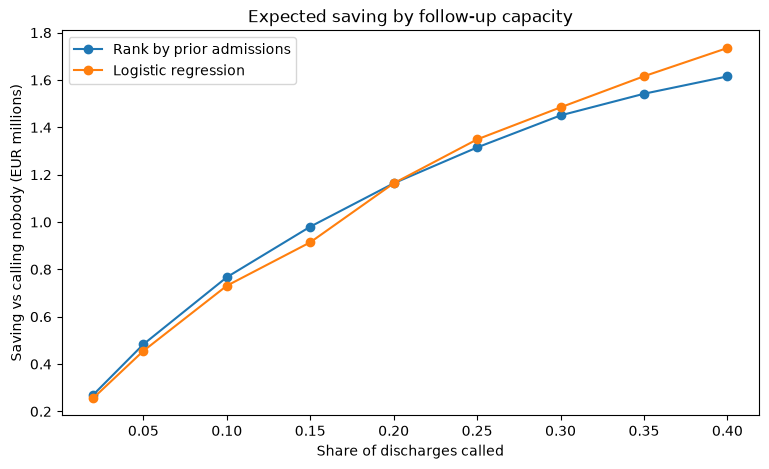

In [30]:
import matplotlib.pyplot as plt

# Baseline: what it costs if nobody is called at all
baseline_cost = total_readmissions * COST_READMISSION

# Saving against that baseline, in millions
costs["heuristic_saving"] = (baseline_cost - costs["heuristic_cost"]) / 1_000_000
costs["model_saving"] = (baseline_cost - costs["model_cost"]) / 1_000_000

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(costs["capacity"], costs["heuristic_saving"], marker="o", label="Rank by prior admissions")
ax.plot(costs["capacity"], costs["model_saving"], marker="o", label="Logistic regression")

ax.set_xlabel("Share of discharges called")
ax.set_ylabel("Saving vs calling nobody (EUR millions)")
ax.set_title("Expected saving by follow-up capacity")
ax.legend()

plt.savefig("cost_comparisonG.png", dpi=150, bbox_inches="tight")
plt.show()
